# 04 Double-difference relocation and the 25 m reference catalog

The DL events inside the Imsil box that pass the location-quality gate were relocated together with the Haenam relocation recipe. The gate is gap < 180°, more than 7 phases, RMS < 1 s, horizontal and vertical errors < 5 km, and depth ≥ 10 km (decision D5).

**What a double-difference relocation is.** HypoDD solves for the *relative* positions of nearby events from differences of their travel times: from the phase picks, and from waveform cross-correlation at 5–20 Hz (keeping only CC ≥ 0.7).

**How uncertainty is measured.** It is the 2.5–97.5 % range of 1,000 bootstrap replicas, in which the data are resampled and the inversion repeated.

**The reference catalog** keeps every event whose 95 % half-widths in east, north and depth are all 25 m or less, the Haenam rule. No other selection applies.

This notebook checks the solution (conditioning, links, errors), shows the geometry, fits a plane (decision D15), and compares the result with the earlier, independent 18-event relocation of the swarm. It also gives the evidence for decisions D5 (depth floor) and D6 (onset windows).

In [1]:
import os, sys, re, glob
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; PROJECT = os.path.dirname(DL)
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, matplotlib.dates as mdates
pd.set_option('display.width', 200)
RUN = f'{DL}/runs/hypodd_dl'; BR = f'{RUN}/2.HypoDD/02.dt.cc'
rel = pd.read_csv(f'{DL}/catalogs/imsil_dl_relocated.csv', dtype={'event_id': str, 'template_match': str})
allu = pd.read_csv(f'{DL}/catalogs/reference_25m/DL_all_with_uncertainty.csv', dtype={'event_id': str, 'template_match': str})
ref = pd.read_csv(f'{DL}/catalogs/reference_25m/DL_reference_25m.csv', dtype={'event_id': str, 'template_match': str})
man = pd.read_csv(f'{RUN}/event_manifest.csv', dtype={'event_id': str})
for d in (rel, allu, ref):
    d['t'] = pd.to_datetime(d['origin_time_reloc'] if 'origin_time_reloc' in d else d['origin_time'])
ML19 = '20251102203835'
m19 = allu[allu.template_match == ML19].iloc[0]
LAT0, LON0, Z0 = float(m19.latitude), float(m19.longitude), float(m19.depth_km)
KM_LAT = 111.19; KM_LON = KM_LAT * np.cos(np.radians(LAT0))
def local(d):
    d = d.copy(); d['east'] = (d.longitude - LON0) * KM_LON * 1000; d['north'] = (d.latitude - LAT0) * KM_LAT * 1000; d['depth_m'] = (d.depth_km - Z0) * 1000
    return d
allu, ref, rel = local(allu), local(ref), local(rel)
print(f'submitted (manifest) {len(man)}; relocated {len(rel)}; 25 m reference {len(ref)}; ML 1.9 relocated at {LAT0:.5f} N {LON0:.5f} E {Z0:.3f} km')

submitted (manifest) 34; relocated 34; 25 m reference 28; ML 1.9 relocated at 35.55258 N 127.29293 E 13.015 km


## 1. Counts and the 25 m rule

In [2]:
kma_in = lambda d: int((d.template_match.notna() & (d.template_match != '-')).sum())
counts = pd.DataFrame([('submitted to the relocation', len(man), '-'),
                       ('relocated', len(rel), kma_in(rel)),
                       ('all three 95 % half-widths finite and <= 25 m (reference)', len(ref), kma_in(ref)),
                       ('excluded by the 25 m rule', len(allu) - len(ref), kma_in(allu) - kma_in(ref))], columns=['stage', 'events', 'of which KMA-listed'])
display(counts)
thr = pd.read_csv(f'{DL}/catalogs/reference_25m/threshold_sensitivity.csv'); display(thr)
print('reasons for exclusion:'); display(allu[~allu.pass25].reason.value_counts())
missing_kma = sorted(set(pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str}).event_id) - set(rel.template_match.dropna()))
print('KMA-listed events not relocated:', missing_kma if missing_kma else 'none')

,stage,events,of which KMA-listed
0,submitted to the relocation,34,-
1,relocated,34,24
2,all three 95 % half-widths finite and <= 25 m ...,28,22
3,excluded by the 25 m rule,6,2


,bound_m,total,retained
0,5,34,25
1,10,34,28
2,15,34,28
3,25,34,28
4,50,34,28
5,100,34,32
6,250,34,32
7,500,34,33
8,1000,34,34


reasons for exclusion:


reason
east; north; vertical    4
vertical                 2
Name: count, dtype: int64

KMA-listed events not relocated: none


## 2. Conditioning and data
HypoDD's LSQR solver is damped adaptively so that the condition number of every iteration set stays within 40–80, the Haenam target.

In [3]:
txt = open(f'{BR}/damping_calibration.txt').read()
last = re.findall(r'\{([^}]*)\}', txt)[-1]
cnd = {int(k): float(v) for k, v in (kv.split(':') for kv in last.split(','))}
chosen = re.search(r'chosen DAMP per set: \[([^\]]*)\]', txt).group(1)
print('chosen DAMP per set:', chosen); print('condition number per set:', cnd)
cnd_ok = all(40 <= v <= 80 for v in cnd.values()); print('all sets within 40-80:', cnd_ok)
print(f'cross-correlation links per event: median {rel.cc_links.median():.0f} (10th pct {rel.cc_links.quantile(.1):.0f}); catalog links median {rel.ct_links.median():.0f}')

chosen DAMP per set: 29, 26, 26, 30, 27, 28, 27
condition number per set: {0: 60.1, 1: 65.2, 2: 61.8, 3: 69.9, 4: 68.2, 5: 62.4, 6: 66.2}
all sets within 40-80: True
cross-correlation links per event: median 328 (10th pct 148); catalog links median 540


## 3. Bootstrap uncertainties

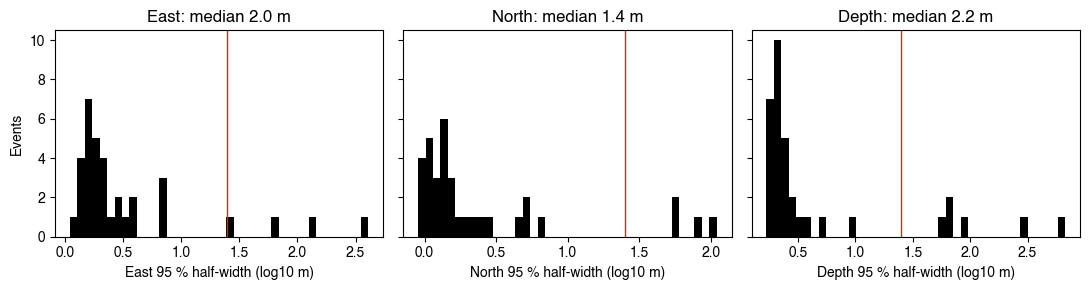

,ex95,ey95,ez95
reference median,1.86,1.32,2.05
reference 90 %,3.39,2.64,3.40


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a, c, lab in zip(ax, ('ex95', 'ey95', 'ez95'), ('East', 'North', 'Depth')):
    v = allu[c].dropna(); a.hist(np.log10(v.clip(lower=0.1)), bins=40, color='black')
    a.axvline(np.log10(25), color='tab:red', lw=1); a.set_xlabel(f'{lab} 95 % half-width (log10 m)'); a.set_title(f'{lab}: median {v.median():.1f} m')
ax[0].set_ylabel('Events'); plt.tight_layout(); plt.show()
q = ref[['ex95', 'ey95', 'ez95']].quantile([.5, .9]).round(2); display(q.rename(index={.5: 'reference median', .9: 'reference 90 %'}))

## 4. Geometry of the reference catalog
Coordinates are relative to the relocated ML 1.9 event: east, north and depth in metres, with depth positive downward. Colours give the origin time; black crosses mark the KMA-listed events; bars are bootstrap 95 % half-widths.

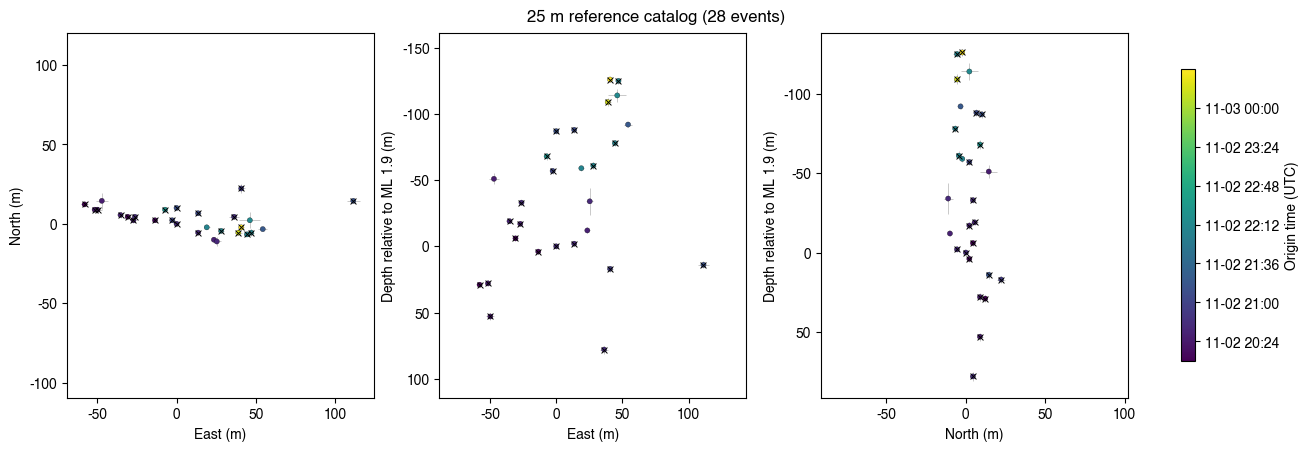

extent of 95 % of the reference events (m): {'east': 126, 'north': 27, 'depth_m': 186}


In [5]:
cm = plt.cm.viridis; tnum = mdates.date2num(ref.t); norm = plt.Normalize(tnum.min(), tnum.max())
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4), layout='constrained')
for a, (x, y, ex, ey, xl, yl) in zip(ax, [('east', 'north', 'ex95', 'ey95', 'East (m)', 'North (m)'), ('east', 'depth_m', 'ex95', 'ez95', 'East (m)', 'Depth relative to ML 1.9 (m)'), ('north', 'depth_m', 'ey95', 'ez95', 'North (m)', 'Depth relative to ML 1.9 (m)')]):
    a.errorbar(ref[x], ref[y], xerr=ref[ex], yerr=ref[ey], fmt='none', ecolor='0.7', lw=0.5, capsize=0)
    sc = a.scatter(ref[x], ref[y], c=tnum, cmap=cm, norm=norm, s=14, edgecolor='black', linewidth=0.2, zorder=3)
    k = ref[ref.template_match.notna() & (ref.template_match != '-')]
    a.scatter(k[x], k[y], marker='x', color='black', s=18, lw=0.7, zorder=4)
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect('equal', adjustable='datalim')
    if 'depth' in y: a.invert_yaxis()
cb = fig.colorbar(sc, ax=ax, shrink=0.8, label='Origin time (UTC)'); cb.ax.yaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
fig.suptitle(f'25 m reference catalog ({len(ref)} events)'); plt.show()
ext = {c: float(ref[c].quantile(.975) - ref[c].quantile(.025)) for c in ('east', 'north', 'depth_m')}
print('extent of 95 % of the reference events (m):', {k: round(v) for k, v in ext.items()})

## 5. Fault plane (decision D15)
The plane is fitted with Haenam's total-least-squares SVD, `joint_science.plane`, copied verbatim: an unweighted fit with no clipping. The 95 % ranges come from 1,000 event-resampling fits (seed 20260922).

A near-vertical plane needs one extra check. When the dip is close to 90°, a resample can flip which side of the normal points upward, which reports the strike rotated by 180°. Flips are counted. If any occur, a normal-aligned version, with each resample normal oriented like the full fit, is shown as a diagnostic.

In [6]:
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
# synthetic check of the strike convention (memory note: strike = az(upward normal) - 90); plane 96/67
rs = np.random.default_rng(0); st0, dp0 = np.radians(96), np.radians(67)
sv_ = np.array([np.sin(st0), np.cos(st0), 0]); dv_ = np.array([np.cos(st0) * np.cos(dp0), -np.sin(st0) * np.cos(dp0), np.sin(dp0)])
syn = plane(rs.normal(size=(300, 1)) * 100 * sv_ + rs.normal(size=(300, 1)) * 50 * dv_); print(f'synthetic 96/67 plane recovered as {syn["strike"]:.2f}/{syn["dip"]:.2f}')
X = ref[['east', 'north', 'depth_m']].to_numpy(); p = plane(X); rng = np.random.default_rng(20260922)
bp = [plane(X[rng.integers(0, len(X), len(X))]) for _ in range(1000)]
boot = np.array([[b['strike'], b['dip']] for b in bp])
p['strike_ci'] = np.percentile(boot[:, 0], [2.5, 97.5]); p['dip_ci'] = np.percentile(boot[:, 1], [2.5, 97.5])
d_str = (boot[:, 0] - p['strike'] + 180) % 360 - 180; n_flip = int((np.abs(d_str) > 90).sum())
print(f'Haenam method: strike {p["strike"]:.2f} deg (95 %: {p["strike_ci"][0]:.2f}-{p["strike_ci"][1]:.2f}), dip {p["dip"]:.2f} deg ({p["dip_ci"][0]:.2f}-{p["dip_ci"][1]:.2f}), RMS thickness {p["rms"]:.1f} m, singular values {np.round(p["sv"] / p["sv"][0], 3)}')
print(f'resamples whose strike is rotated by more than 90 deg (upward-normal flips): {n_flip} of 1000')
if n_flip:
    al = np.array([b['normal'] * np.sign(b['normal'] @ p['normal']) for b in bp])
    a_str = (np.degrees(np.arctan2(al[:, 0], al[:, 1])) - 90) % 360; a_dip = np.degrees(np.arccos(np.clip(-al[:, 2], -1, 1)))
    a_str = p['strike'] + ((a_str - p['strike'] + 180) % 360 - 180)
    print(f'diagnostic (normals aligned to the full fit): strike 95 % {np.percentile(a_str, 2.5):.2f}-{np.percentile(a_str, 97.5):.2f}, dip 95 % {np.percentile(a_dip, 2.5):.2f}-{np.percentile(a_dip, 97.5):.2f} (dip > 90 means the plane leans the other way)')
    al_ci = (np.percentile(a_str, [2.5, 97.5]), np.percentile(a_dip, [2.5, 97.5]))
else:
    al_ci = (p['strike_ci'], p['dip_ci'])
# working check of this notebook (not a Haenam rule): strike 95 % range < 30 deg with the Haenam convention and no flips
plane_constrained = (p['strike_ci'][1] - p['strike_ci'][0] < 30) and (n_flip == 0)
print('Haenam-convention interval narrower than 30 deg with no flips (working check, not a Haenam rule):', plane_constrained)
print(f'normal-aligned strike range {al_ci[0][1] - al_ci[0][0]:.1f} deg; dip within {max(abs(90 - al_ci[1][0]), abs(al_ci[1][1] - 90)):.1f} deg of vertical at the 95 % ends')

synthetic 96/67 plane recovered as 96.00/67.00
Haenam method: strike 271.98 deg (95 %: 97.09-276.97), dip 87.19 deg (83.27-89.86), RMS thickness 7.1 m, singular values [1.    0.608 0.125]
resamples whose strike is rotated by more than 90 deg (upward-normal flips): 134 of 1000
diagnostic (normals aligned to the full fit): strike 95 % 267.70-284.45, dip 95 % 83.56-95.27 (dip > 90 means the plane leans the other way)
Haenam-convention interval narrower than 30 deg with no flips (working check, not a Haenam rule): False
normal-aligned strike range 16.8 deg; dip within 6.4 deg of vertical at the 95 % ends


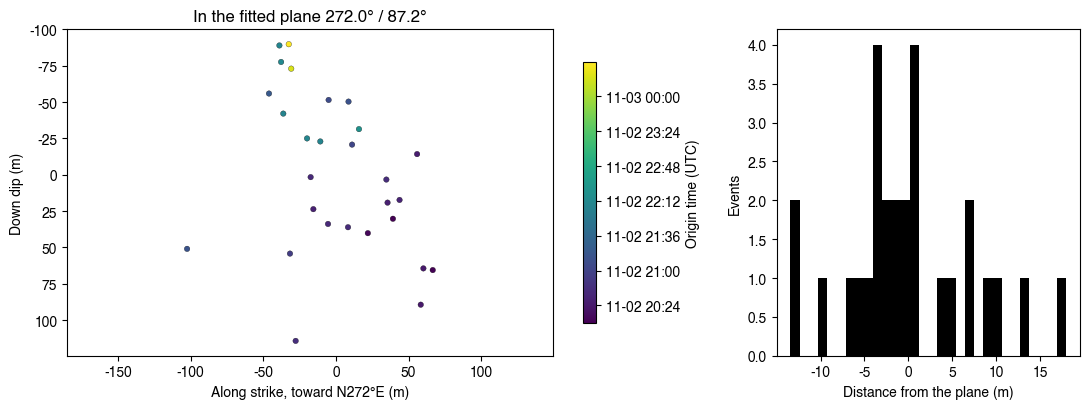

In [7]:
Y = X - p['center']; ref['along'] = Y @ p['s']; ref['down_dip'] = Y @ p['down']; ref['normal_res'] = Y @ p['normal']
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[2, 1]))
sc = ax[0].scatter(ref.along, ref.down_dip, c=tnum, cmap=cm, norm=norm, s=16, edgecolor='black', linewidth=0.2)
ax[0].invert_yaxis(); ax[0].set_aspect('equal', adjustable='datalim'); ax[0].set_xlabel(f'Along strike, toward N{p["strike"]:.0f}°E (m)'); ax[0].set_ylabel('Down dip (m)')
ax[0].set_title(f'In the fitted plane {p["strike"]:.1f}° / {p["dip"]:.1f}°')
ax[1].hist(ref.normal_res, bins=30, color='black'); ax[1].set_xlabel('Distance from the plane (m)'); ax[1].set_ylabel('Events')
cb = fig.colorbar(sc, ax=ax[0], shrink=0.8, label='Origin time (UTC)'); cb.ax.yaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
plt.tight_layout(); plt.show()

## 6. Comparison with the earlier 18-event relocation
The earlier relocation (`6.Detection_HypoDD/02.dt.cc/hypoDD.reloc`) used PhaseNO picks at 11 stations, HypoDD with SVD and CC ≥ 0.7 from other windows. It is independent of this run, so agreement within the bootstrap bounds is an external check.
Events are matched by origin time (within 2 s). The earlier positions are moved once by the median offset, which removes the frame shift between the two relocations, and the remaining differences are compared with the 95 % half-widths.

matched events: 17 of 18; frame offset removed (E, N, Z) = [-178.4 -500.8 -460. ] m


,dE,dN,dZ
50%,0.9,0.6,2.0
90%,3.1,2.5,3.4
max,4.1,3.7,4.0


fraction of matched events whose residual is within twice their 95 % half-widths: 0.82


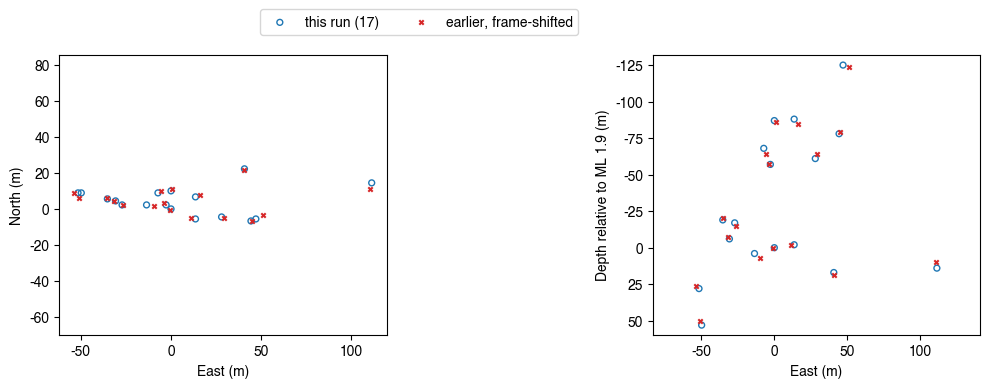

In [8]:
cols = ['id','lat','lon','depth','x','y','z','ex','ey','ez','yr','mo','dy','hr','mi','sc','mag','nccp','nccs','nctp','ncts','rcc','rct','cid']
old = pd.read_csv(f'{PROJECT}/6.Detection_HypoDD/02.dt.cc/hypoDD.reloc', sep=r'\s+', names=cols)
old['t'] = pd.to_datetime(dict(year=old.yr, month=old.mo, day=old.dy, hour=old.hr, minute=old.mi)) + pd.to_timedelta(old.sc, unit='s')
old['east'] = (old.lon - LON0) * KM_LON * 1000; old['north'] = (old.lat - LAT0) * KM_LAT * 1000; old['depth_m'] = (old.depth - Z0) * 1000
pairs = []
for r in old.itertuples():
    dt = (allu.t - r.t).dt.total_seconds().abs(); i = dt.idxmin()
    if dt[i] <= 2: pairs.append((r.Index, i, dt[i]))
po = old.loc[[a for a, _, _ in pairs]].reset_index(drop=True); pn = allu.loc[[b for _, b, _ in pairs]].reset_index(drop=True)
off = np.median(po[['east', 'north', 'depth_m']].to_numpy() - pn[['east', 'north', 'depth_m']].to_numpy(), axis=0)
res = po[['east', 'north', 'depth_m']].to_numpy() - off - pn[['east', 'north', 'depth_m']].to_numpy()
cmpd = pd.DataFrame(dict(t=pn.t, dE=res[:, 0], dN=res[:, 1], dZ=res[:, 2], ex95=pn.ex95, ey95=pn.ey95, ez95=pn.ez95, in_ref=pn.pass25))
print(f'matched events: {len(cmpd)} of {len(old)}; frame offset removed (E, N, Z) = {np.round(off, 1)} m')
display(cmpd[['dE', 'dN', 'dZ']].abs().describe(percentiles=[.5, .9]).loc[['50%', '90%', 'max']].round(1))
within = ((cmpd.dE.abs() <= 2 * cmpd.ex95.fillna(np.inf)) & (cmpd.dN.abs() <= 2 * cmpd.ey95.fillna(np.inf)) & (cmpd.dZ.abs() <= 2 * cmpd.ez95.fillna(np.inf))).mean()
print(f'fraction of matched events whose residual is within twice their 95 % half-widths: {within:.2f}')
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (x, y, xl, yl) in zip(ax, [('east', 'north', 'East (m)', 'North (m)'), ('east', 'depth_m', 'East (m)', 'Depth relative to ML 1.9 (m)')]):
    a.scatter(pn[x], pn[y], s=18, facecolor='none', edgecolor='tab:blue', label=f'this run ({len(pn)})')
    a.scatter(po[x] - off[['east', 'north', 'depth_m'].index(x)], po[y] - off[['east', 'north', 'depth_m'].index(y)], s=10, marker='x', color='tab:red', label='earlier, frame-shifted')
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect('equal', adjustable='datalim')
    if 'depth' in y: a.invert_yaxis()
ax[0].legend(loc='lower center', bbox_to_anchor=(1.1, 1.05), ncol=2, frameon=True); plt.tight_layout(); plt.show()

In [9]:
# Depth of the swarm events relative to the ML 1.9: before and after it (descriptive)
sw = ref[(ref.t >= '2025-11-02 20:00') & (ref.t <= '2025-11-03 01:00')]
b4, af = sw[sw.t < pd.Timestamp('2025-11-02 20:38:35')], sw[sw.t > pd.Timestamp('2025-11-02 20:38:40')]
po_b4, po_af = po[po.t < pd.Timestamp('2025-11-02 20:38:35')], po[po.t > pd.Timestamp('2025-11-02 20:38:40')]
print(f'this run (reference, swarm window): median depth relative to ML 1.9 before {b4.depth_m.median():+.0f} m (n={len(b4)}), after {af.depth_m.median():+.0f} m (n={len(af)})')
print(f'earlier 18-event relocation:        median depth relative to its ML 1.9 before {(po_b4.depth_m - off[2]).median():+.0f} m, after {(po_af.depth_m - off[2]).median():+.0f} m (positive = deeper)')

this run (reference, swarm window): median depth relative to ML 1.9 before -6 m (n=11), after -73 m (n=16)
earlier 18-event relocation:        median depth relative to its ML 1.9 before -2 m, after -64 m (positive = deeper)


## 7. Evidence for D5 (depth floor 10 km) and D6 (onset windows)
**D5.** Haenam drops events shallower than 10 km before relocation: in its box they were quarry blasts, 98 % in daytime and 11 % on weekends. The table shows what the floor removes at Imsil.

In [10]:
cat = pd.read_csv(f'{DL}/catalogs/imsil_dl_catalog.csv', parse_dates=['time'])
inbox = cat[cat.in_imsil_box & cat.tier.isin(['A', 'B'])]
sh = inbox[inbox.depth < 10]; kst_h = (sh.time + pd.Timedelta(hours=9)).dt.hour; kst_wd = (sh.time + pd.Timedelta(hours=9)).dt.dayofweek
print(f'in-box A/B events: {len(inbox)}; shallower than 10 km: {len(sh)}')
if len(sh):
    print(f'  of these: {int(kst_h.between(8, 17).sum())} between 08:00 and 18:00 KST, {int((kst_wd >= 5).sum())} on weekends')
    display(sh[['time', 'lat', 'lon', 'depth', 'tier', 'KMA_match']])

in-box A/B events: 84; shallower than 10 km: 46
  of these: 45 between 08:00 and 18:00 KST, 6 on weekends


,time,lat,lon,depth,tier,KMA_match
31,2025-09-03 00:18:12.870,35.4650,127.4075,2.90,B,-
107,2025-09-08 02:41:16.470,35.4603,127.4165,3.96,B,-
127,2025-09-10 02:54:13.660,35.4784,127.2988,1.47,A,-
140,2025-09-11 01:17:57.040,35.4681,127.4113,0.38,B,-
143,2025-09-11 02:55:33.530,35.4780,127.2984,1.94,A,-
221,2025-09-19 00:40:45.360,35.4736,127.2998,3.97,A,-
249,2025-09-23 03:00:08.810,35.4753,127.2962,1.12,B,-
346,2025-10-01 03:11:33.130,35.4760,127.2966,2.16,A,-
359,2025-10-02 02:44:35.590,35.4732,127.2968,3.31,A,-
405,2025-10-10 02:52:16.490,35.4723,127.2972,3.87,A,-


**D6.** Haenam used short onset windows (±0.05 s, 1–40 Hz) for its explicit list of M ≥ 2 events. Imsil has no such event, so the default is no window.
The test run gives the ML 1.9 alone the onset window (`IMSIL_ONSET_EVENTS=20251102203835`, scratch run root `runs/hypodd_dl_d6`, no bootstrap). It shows how far that moves the ML 1.9 and its neighbours.

In [11]:
d6p = f'{DL}/runs/hypodd_dl_d6/imsil_dl_relocated.csv'
if os.path.exists(d6p):
    d6 = local(pd.read_csv(d6p, dtype={'event_id': str, 'template_match': str}))
    j = rel.merge(d6[['event_id', 'east', 'north', 'depth_m']], on='event_id', suffixes=('', '_d6'))
    o6 = np.median(j[['east_d6', 'north_d6', 'depth_m_d6']].to_numpy() - j[['east', 'north', 'depth_m']].to_numpy(), axis=0)
    j['shift_m'] = np.linalg.norm(j[['east_d6', 'north_d6', 'depth_m_d6']].to_numpy() - o6 - j[['east', 'north', 'depth_m']].to_numpy(), axis=1)
    i19 = j.template_match == ML19
    j['dist_to_ml19_m'] = np.linalg.norm(j[['east', 'north', 'depth_m']].to_numpy() - j.loc[i19, ['east', 'north', 'depth_m']].to_numpy(), axis=1)
    near = j.sort_values('dist_to_ml19_m').head(11)
    d6_ml19 = float(j.loc[i19, 'shift_m'].iloc[0]); d6_med = float(j.shift_m.median())
    print(f'D6: ML 1.9 moves {d6_ml19:.1f} m; its 10 nearest neighbours median {near.shift_m.iloc[1:].median():.1f} m; all events median {d6_med:.1f} m')
else:
    d6_ml19 = d6_med = np.nan; print('D6 test run not found (runs/hypodd_dl_d6)')

D6: ML 1.9 moves 6.2 m; its 10 nearest neighbours median 1.0 m; all events median 1.1 m


## Comprehensive summary

In [12]:
summary = pd.DataFrame([
    ('Submitted / relocated / 25 m reference', f'{len(man)} / {len(rel)} / {len(ref)}'),
    ('KMA-listed events in the reference', f'{kma_in(ref)} of 24'),
    ('Condition numbers within 40-80 (all sets)', cnd_ok),
    ('Reference median 95 % half-widths E / N / Z (m)', ' / '.join(f'{v:.1f}' for v in ref[['ex95', 'ey95', 'ez95']].median())),
    ('Extent of 95 % of reference events E / N / Z (m)', ' / '.join(f'{v:.0f}' for v in ext.values())),
    ('Plane strike / dip (Haenam method)', f'{p["strike"]:.1f} / {p["dip"]:.1f} deg, RMS {p["rms"]:.1f} m'),
    ('Plane 95 % ranges, Haenam convention (strike; dip); flips', f'{p["strike_ci"][0]:.1f}-{p["strike_ci"][1]:.1f}; {p["dip_ci"][0]:.1f}-{p["dip_ci"][1]:.1f}; {n_flip}'),
    ('Plane 95 % ranges, normals aligned (strike; dip)', f'{al_ci[0][0]:.1f}-{al_ci[0][1]:.1f}; {al_ci[1][0]:.1f}-{al_ci[1][1]:.1f}'),
    ('Earlier 18-event relocation: matched; median |dE, dN, dZ| (m)', f'{len(cmpd)}; ' + ', '.join(f'{v:.0f}' for v in cmpd[['dE', 'dN', 'dZ']].abs().median())),
    ('D5: in-box A/B events shallower than 10 km', len(sh)),
    ('D6: ML 1.9 shift with an onset window (m)', round(d6_ml19, 1) if np.isfinite(d6_ml19) else 'not run'),
], columns=['quantity', 'value'])
display(summary)
print('Take-home points')
print(f'  - {len(ref)} of {len(rel)} relocated events meet the 25 m rule, {kma_in(ref)} of them KMA-listed; their median 95 % half-widths are a few metres.')
print(f'  - The swarm occupies about {ext["east"]:.0f} m east-west, {ext["north"]:.0f} m north-south and {ext["depth_m"]:.0f} m in depth (95 % of reference events).')
print(f'  - The Haenam SVD fit gives {p["strike"]:.0f} deg / {p["dip"]:.0f} deg (RMS thickness {p["rms"]:.0f} m). ' + (f'Because the plane is near-vertical, {n_flip} of 1000 resamples flip the upward normal, which widens the Haenam-convention strike interval; with the normals aligned the strike spans {al_ci[0][0]:.0f}-{al_ci[0][1]:.0f} deg and the dip {al_ci[1][0]:.0f}-{al_ci[1][1]:.0f} deg. Adoption is decision D15.' if n_flip else 'Adoption is decision D15.'))
print(f'  - The independent earlier relocation agrees after one frame shift: median residuals ' + ', '.join(f'{v:.0f}' for v in cmpd[['dE', 'dN', 'dZ']].abs().median()) + ' m.')
print('Next: local magnitudes (notebook 05), then FMF templates from catalogs/reference_25m/DL_reference_25m.csv (notebook 06).')

,quantity,value
0,Submitted / relocated / 25 m reference,34 / 34 / 28
1,KMA-listed events in the reference,22 of 24
2,Condition numbers within 40-80 (all sets),True
3,Reference median 95 % half-widths E / N / Z (m),1.9 / 1.3 / 2.1
4,Extent of 95 % of reference events E / N / Z (m),126 / 27 / 186
5,Plane strike / dip (Haenam method),"272.0 / 87.2 deg, RMS 7.1 m"
6,"Plane 95 % ranges, Haenam convention (strike; ...",97.1-277.0; 83.3-89.9; 134
7,"Plane 95 % ranges, normals aligned (strike; dip)",267.7-284.5; 83.6-95.3
8,Earlier 18-event relocation: matched; median |...,"17; 1, 1, 2"
9,D5: in-box A/B events shallower than 10 km,46


Take-home points
  - 28 of 34 relocated events meet the 25 m rule, 22 of them KMA-listed; their median 95 % half-widths are a few metres.
  - The swarm occupies about 126 m east-west, 27 m north-south and 186 m in depth (95 % of reference events).
  - The Haenam SVD fit gives 272 deg / 87 deg (RMS thickness 7 m). Because the plane is near-vertical, 134 of 1000 resamples flip the upward normal, which widens the Haenam-convention strike interval; with the normals aligned the strike spans 268-284 deg and the dip 84-95 deg. Adoption is decision D15.
  - The independent earlier relocation agrees after one frame shift: median residuals 1, 1, 2 m.
Next: local magnitudes (notebook 05), then FMF templates from catalogs/reference_25m/DL_reference_25m.csv (notebook 06).
